In [1]:
# Zelle 1: Bibliotheken laden. Alle weiteren Zellen benutzen diese Namen (pn, plf, np, pd, nx, plt).
import pypowsybl as pp  # Netzmodell und Lastfluss (pypowsybl)
import pypowsybl.network as pn  # Netze laden und ändern: pn.load(...), update_lines(...), get_buses(...)
import pypowsybl.loadflow as plf  # Lastflussrechnung: plf.run_ac(...), plf.run_dc(...)
import numpy as np  # Matrizen und Vektoren
from pypowsybl_jupyter import NetworkMapWidget, network_explorer  # interaktive Netzansicht im Notebook
import matplotlib.pyplot as plt  # Diagramme (Zelle 5)
import pandas as pd  # Tabellen
import math as m
import os
import networkx as nx  # Graphen: Inseln finden (Zelle 5 und 11)
import pandas as pd


In [2]:
# Zelle 2: Testnetz laden (complex_grid aus dem Ordner data/ im Repository).
from pathlib import Path

# Vom aktuellen Ordner nach oben gehen, bis ein Ordner gefunden wird, der data/complex_grid enthält.
# So funktioniert der Pfad auf jedem Rechner (lokal und im Devcontainer).
repo_root = next(p for p in Path.cwd().resolve().parents if (p / "data" / "complex_grid").exists())
# Das intakte Netz laden. Es bleibt unverändert, die späteren Zellen laden sich eigene Kopien.
complex_grid = pn.load(repo_root / "data" / "complex_grid" / "grid.xiidm")
complex_grid  # Notebook zeigt die Netz-Zusammenfassung (Anzahl Leitungen, Trafos, ...)

Network(id=TESTGRID_NODE_BREAKER_HVDC_BAT_SVC_3W_TRAFO, name=TESTGRID_NODE_BREAKER_HVDC_BAT_SVC_3W_TRAFO, case_date=2026-04-03 12:53:36.970000+00:00, forecast_distance=0:00:00, source_format=)

In [3]:
# Zelle 3: Interaktive Netzansicht des intakten Netzes (zum Anschauen, wird für die Rechnung nicht gebraucht).
network_explorer(complex_grid)

In [4]:
# Zelle 4: Das Netz in zwei elektrische Inseln teilen und je Insel einen AC-Lastfluss rechnen.
# Insel 1 = 380-kV-Netz, Insel 0 = 110/63-kV-Netz. Dazu werden die vier Transformatoren zwischen beiden geöffnet.
island_net = pn.load(repo_root / "data" / "complex_grid" / "grid.xiidm")  # frische Kopie, complex_grid bleibt intakt
for trafo in ["2W_3W_MV_HV", "2W_MV_HV_1", "2W_MV_HV_2", "3W-Leg1"]:
    # Beide Seiten des Trafos abschalten = Trafo ausgefallen
    island_net.update_2_windings_transformers(id=trafo, connected1=False, connected2=False)

# Jede Insel braucht eigene Erzeugung. Ohne Anpassung hätte die 110-kV-Insel nur 30 MW für etwa 545 MW Last
# und der Lastfluss würde nicht konvergieren. Deshalb: GEN_MV auf 560 MW, GEN_HV von 700 auf 480 MW.
island_net.update_generators(id="GEN_MV", target_p=560, max_p=1000)
island_net.update_generators(id="GEN_HV", target_p=480)

# ALL_CONNECTED: alle Inseln rechnen (Standard wäre nur die größte Insel).
# distributed_slack: Leistungsfehler auf die Generatoren der jeweiligen Insel verteilen.
params = plf.Parameters(component_mode=plf.ComponentMode.ALL_CONNECTED, distributed_slack=True)
# plf.run_ac liefert pro Insel ein Ergebnis: Nummer der Insel und ob der Lastfluss konvergiert ist
for res in plf.run_ac(island_net, params):
    print(res.synchronous_component_num, res.status)
# Zuordnung: welcher Bus gehört zu welcher Insel (synchronous_component)
island_net.get_buses()[["voltage_level_id", "synchronous_component"]]

0 ComponentStatus.CONVERGED
1 ComponentStatus.CONVERGED


,voltage_level_id,synchronous_component
id,,
VL_3W_HV_0,VL_3W_HV,1
VL_3W_MV_0,VL_3W_MV,0
VL_3W_LV_0,VL_3W_LV,0
3W-Star-VL_0,3W-Star-VL,0
VL_2W_MV_LV_MV_0,VL_2W_MV_LV_MV,0
VL_2W_MV_LV_LV_0,VL_2W_MV_LV_LV,0
VL_LV_load_0,VL_LV_load,0
VL_MV_load_0,VL_MV_load,0
VL_MV_load_3,VL_MV_load,0


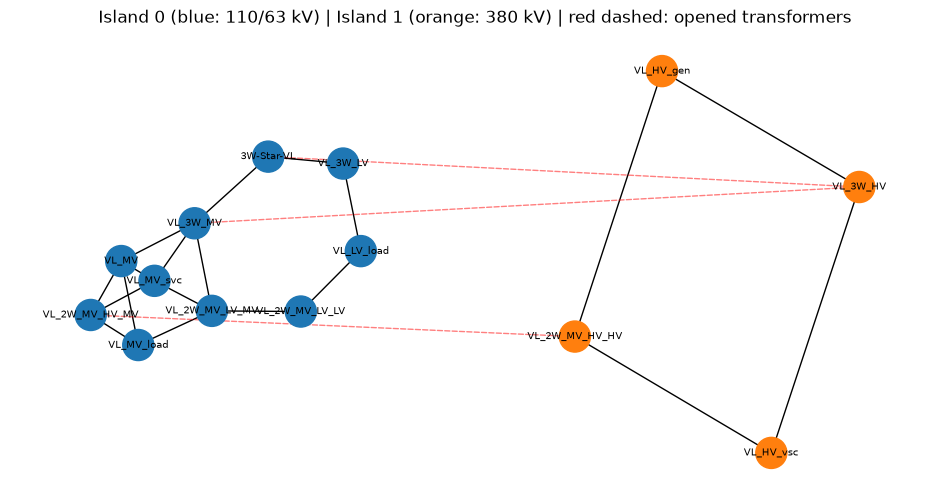

In [5]:
# Zelle 5: Beide Inseln als Graph nebeneinander zeichnen.
# Jeder Knoten ist ein Voltage Level. Farbe = Insel (blau = Insel 0, orange = Insel 1).
# Rot gestrichelt = die vier geöffneten Transformatoren, schwarz = noch verbundene Leitungen/Trafos.
# Die vier geöffneten Trafos (wie in Zelle 4)
cut_ids = {"2W_3W_MV_HV", "2W_MV_HV_1", "2W_MV_HV_2", "3W-Leg1"}
# Intaktes Netz laden, damit auch die geöffneten Trafos als Kanten im Graphen vorkommen
original_net = pn.load(repo_root / "data" / "complex_grid" / "grid.xiidm")
branches = pd.concat([original_net.get_lines(), original_net.get_2_windings_transformers()])
# Zweige innerhalb eines Voltage Levels (z.B. Phasenschieber mit gleichem Anfang und Ende) weglassen
branches = branches[branches.voltage_level1_id != branches.voltage_level2_id]
# Zuordnung Voltage Level -> Insel aus dem Lastfluss-Ergebnis von Zelle 4
island_of = island_net.get_buses().groupby("voltage_level_id").synchronous_component.first()

# Graph aufbauen: Knoten = Voltage Levels, Kanten = Zweige (is_cut markiert die geöffneten Trafos)
graph = nx.Graph()
graph.add_nodes_from(island_of.index)
for branch_id, row in branches.iterrows():
    graph.add_edge(row.voltage_level1_id, row.voltage_level2_id, is_cut=branch_id in cut_ids)

# Jede Insel einzeln anordnen (ohne die geöffneten Kanten) und Insel 1 nach rechts verschieben.
# So liegen beide Inseln sichtbar getrennt nebeneinander.
pos = {}
for island, shift in zip(sorted(island_of.unique()), [0.0, 3.5]):
    sub = graph.subgraph(island_of.index[island_of == island]).copy()
    sub.remove_edges_from([e for e in sub.edges if sub.edges[e]["is_cut"]])
    for node, (x, y) in nx.spring_layout(sub, seed=1).items():
        pos[node] = (x + shift, y)

# Zeichnen: erst die intakten Kanten, dann die geöffneten (rot gestrichelt), dann Knoten und Beschriftung
colors = {0: "tab:blue", 1: "tab:orange"}
fig, ax = plt.subplots(figsize=(12, 6))
intact = [e for e in graph.edges if not graph.edges[e]["is_cut"]]
cut_edges = [e for e in graph.edges if graph.edges[e]["is_cut"]]
nx.draw_networkx_edges(graph, pos, edgelist=intact, ax=ax)
nx.draw_networkx_edges(graph, pos, edgelist=cut_edges, ax=ax, style="dashed", edge_color="red", alpha=0.5)
nx.draw_networkx_nodes(graph, pos, ax=ax, node_color=[colors[island_of[n]] for n in graph.nodes], node_size=500)
nx.draw_networkx_labels(graph, pos, ax=ax, font_size=7)
ax.set_title("Island 0 (blue: 110/63 kV) | Island 1 (orange: 380 kV) | red dashed: opened transformers")
ax.axis("off")
plt.show()

In [6]:
# Zelle 6: AC-Lastfluss auf dem Zwei-Inseln-Netz erneut rechnen und das rohe Ergebnis anzeigen
# (eine ComponentResult-Zeile je Insel: Status, Iterationen, Slack-Bus, Leistungsfehler).
lf_results = plf.run_ac(island_net, params)
lf_results

[ComponentResult(connected_component_num=0, synchronous_component_num=0, status=CONVERGED, status_text=Converged, iteration_count=6, reference_bus_id='VL_3W_MV_0', slack_bus_results=[SlackBusResult(id='VL_3W_MV_0', active_power_mismatch=0.0379857292925001)], distributed_active_power=29.23551695471035),
 ComponentResult(connected_component_num=1, synchronous_component_num=1, status=CONVERGED, status_text=Converged, iteration_count=3, reference_bus_id='VL_HV_gen_0', slack_bus_results=[SlackBusResult(id='VL_HV_gen_0', active_power_mismatch=0.0022104851208126775)], distributed_active_power=-4.984568487256347)]

In [7]:
# Zelle 7: Ergebnisse des AC-Lastflusses je Insel auswerten.
# Der Lastfluss schreibt seine Ergebnisse zurück in island_net, daraus werden vier Tabellen gebaut.

# Tabelle 1: Status je Insel. Der Slack-Bus ist die Winkelreferenz der Insel,
# mismatch_mw ist der Leistungsfehler, den der Slack ausgleicht (soll nahe 0 sein).
lf_results = plf.run_ac(island_net, params)
print(pd.DataFrame(
    [
        {
            "island": r.synchronous_component_num,
            "status": r.status.name,
            "iterations": r.iteration_count,
            "slack_bus": r.reference_bus_id,
            "mismatch_mw": r.slack_bus_results[0].active_power_mismatch,
        }
        for r in lf_results
    ]
))

# Tabelle 2: Leistungsbilanz je Insel. p ist in Verbrauchervorzeichen, Erzeugung ist daher negativ.
# Erzeugung minus Last = Verluste der Insel. Die HVDC-Verbindung zählt hier als Last.
island_of = island_net.get_buses().groupby("voltage_level_id").synchronous_component.first()
gens = island_net.get_generators(attributes=["voltage_level_id", "p"])
loads = island_net.get_loads(attributes=["voltage_level_id", "p"])
balance = pd.DataFrame(
    {
        "generation_mw": -gens.groupby(gens.voltage_level_id.map(island_of)).p.sum(),
        "load_mw": loads.groupby(loads.voltage_level_id.map(island_of)).p.sum(),
    }
)
balance["losses_mw"] = balance.generation_mw - balance.load_mw
display(balance.rename_axis("island").round(1))

# Tabelle 3: Die 10 am stärksten belasteten Zweige (nach Strom i1 in A). Nur Zweige, die noch verbunden sind.
cols = ["voltage_level1_id", "p1", "p2", "i1", "connected1"]
branches_lf = pd.concat([island_net.get_lines(attributes=cols), island_net.get_2_windings_transformers(attributes=cols)])
branches_lf = branches_lf[branches_lf.connected1].assign(island=lambda d: d.voltage_level1_id.map(island_of))
display(branches_lf.sort_values("i1", ascending=False).head(10).round(1))

# Tabelle 4: Spannungen (v_mag in kV, v_angle in Grad) je Bus mit Inselnummer.
# Die Winkel der beiden Inseln sind nicht vergleichbar, weil jede Insel ihre eigene Referenz (Slack) hat.
island_net.get_buses()[["voltage_level_id", "synchronous_component", "v_mag", "v_angle"]].round(2)

   island     status  iterations    slack_bus  mismatch_mw
0       0  CONVERGED           6   VL_3W_MV_0     0.037986
1       1  CONVERGED           3  VL_HV_gen_0     0.002210


,generation_mw,load_mw,losses_mw
island,,,
0,586.1,575.0,11.1
1,475.0,470.0,5.0


,voltage_level1_id,p1,p2,i1,connected1,island
id,,,,,,
L3,VL_MV_svc,198.4,-191.8,1107.3,True,0
3W-Leg3,VL_3W_LV,-66.5,66.5,718.8,True,0
L12,VL_MV_svc,96.1,-92.0,530.4,True,0
L13,VL_MV_load,-85.8,89.5,505.4,True,0
L1,VL_3W_LV,41.5,-39.2,467.8,True,0
L4,VL_MV_svc,34.3,-33.4,416.6,True,0
3W-Leg2,VL_3W_MV,66.5,-66.5,411.7,True,0
L7,VL_2W_MV_HV_MV,-56.2,57.0,389.4,True,0
2W_MV_HV_PST,VL_2W_MV_HV_MV,-56.1,56.2,389.3,True,0


,voltage_level_id,synchronous_component,v_mag,v_angle
id,,,,
VL_3W_HV_0,VL_3W_HV,1,378.87,-1.15
VL_3W_MV_0,VL_3W_MV,0,103.74,0.00
VL_3W_LV_0,VL_3W_LV,0,59.41,-0.01
3W-Star-VL_0,3W-Star-VL,0,358.35,-0.00
VL_2W_MV_LV_MV_0,VL_2W_MV_LV_MV,0,102.48,-0.83
VL_2W_MV_LV_LV_0,VL_2W_MV_LV_LV,0,58.63,-0.96
VL_LV_load_0,VL_LV_load,0,53.48,-5.20
VL_MV_load_0,VL_MV_load,0,98.63,-5.23
VL_MV_load_3,VL_MV_load,0,98.63,-19.23


In [8]:
# Zelle 8 (Split MODF, Schritt 1): DC-Basisfall des intakten Netzes rechnen.
# Liefert die Eingaben, die compute_split_modf_main_grid braucht: Zweigflüsse (n_0_flow),
# Knoteneinspeisungen (nodal_injection) und die Zweig-Knoten-Zuordnung (from_node, to_node).
import jax
import jax.numpy as jnp
from toop_engine_dc_solver.jax.split_modf_main_grid import compute_split_modf_main_grid  # die zu testende Funktion

jax.config.update("jax_enable_x64", True)  # doppelte Genauigkeit, sonst stimmt der Vergleich mit pypowsybl nicht

grid_file = repo_root / "data" / "complex_grid" / "grid.xiidm"
# Die vier Trafos, die zusammen als ein N-4-Ausfall das Netz in zwei Inseln teilen
cut_trafos = ["2W_3W_MV_HV", "2W_MV_HV_1", "2W_MV_HV_2", "3W-Leg1"]
# Die Funktion rechnet nur die Insel mit diesem Slack-Bus. Für die 380-kV-Insel: "VL_HV_gen_0"
slack_bus_id = "VL_3W_MV_0"
# Einfacher DC-Lastfluss ohne verteilten Slack, alle Inseln rechnen
dc_params = plf.Parameters(distributed_slack=False, component_mode=plf.ComponentMode.ALL_CONNECTED)


# Hilfsfunktion: Wirkleistung am Anfang (p1) aller Leitungen und Trafos als eine Liste
def branch_flows(net):
    return pd.concat([net.get_lines(attributes=["p1"]), net.get_2_windings_transformers(attributes=["p1"])]).p1


# Intaktes Netz laden. Es werden nur Zweige verwendet, die an beiden Enden verbunden sind.
base_net = pn.load(grid_file)
cols = ["bus1_id", "bus2_id", "connected1", "connected2"]
branches = pd.concat([base_net.get_lines(attributes=cols), base_net.get_2_windings_transformers(attributes=cols)])
branches = branches[branches.connected1 & branches.connected2]
# Jeder Zweig bekommt den Index seines Anfangs- und Endbusses (Position in der Busliste)
buses = base_net.get_buses().index
from_node = buses.get_indexer(branches.bus1_id)
to_node = buses.get_indexer(branches.bus2_id)

# Zweig-Knoten-Inzidenzmatrix: +1 am Anfangsbus, -1 am Endbus (eine Zeile je Zweig, eine Spalte je Bus)
incidence = np.zeros((len(branches), len(buses)))
incidence[np.arange(len(branches)), from_node] = 1.0
incidence[np.arange(len(branches)), to_node] = -1.0

# DC-Lastfluss auf dem intakten Netz. n_0_flow = Zweigflüsse im Normalzustand (N-0),
# base_angle = Winkeldifferenz über jedem Zweig (wird in Zelle 9 für die Suszeptanzen gebraucht).
plf.run_dc(base_net, dc_params)
n_0_flow = branch_flows(base_net).loc[branches.index].to_numpy()
base_angle = incidence @ np.deg2rad(base_net.get_buses().v_angle.loc[buses].to_numpy())
# DC-Flusserhaltung: Die Netto-Einspeisung eines Busses ist die Summe der Flüsse, die ihn verlassen.
# Daraus ergibt sich nodal_injection (Einspeisung je Bus in MW), ohne Generatoren und Lasten einzeln zu summieren.
nodal_injection = incidence.T @ n_0_flow

In [9]:
# Zelle 9 (Split MODF, Schritt 2): Suszeptanzen der Zweige schätzen und daraus die PTDF-Matrix berechnen.
# Die PTDF sagt, wie sich der Fluss auf jedem Zweig ändert, wenn an einem Bus 1 MW eingespeist wird.
# Die Suszeptanz b jedes Zweigs wird aus DC-Läufen mit zufällig veränderten Einspeisungen bestimmt:
# Flussänderung = b * Winkeldifferenz-Änderung. Phasenschieber-Versätze heben sich in den Differenzen auf.
rng = np.random.default_rng(0)  # fester Startwert, damit das Ergebnis reproduzierbar ist
d_flow, d_angle = [], []
for _ in range(4):
    # Netz laden, Generatoren und Lasten zufällig um -50 % bis +50 % ändern, DC-Lastfluss rechnen
    net = pn.load(grid_file)
    gens, loads = net.get_generators(), net.get_loads()
    net.update_generators(id=gens.index.tolist(), target_p=(gens.target_p * rng.uniform(0.5, 1.5, len(gens))).tolist())
    net.update_loads(id=loads.index.tolist(), p0=(loads.p0 * rng.uniform(0.5, 1.5, len(loads))).tolist())
    plf.run_dc(net, dc_params)
    d_flow.append(branch_flows(net).loc[branches.index].to_numpy() - n_0_flow)
    d_angle.append(incidence @ np.deg2rad(net.get_buses().v_angle.loc[buses].to_numpy()) - base_angle)
d_flow, d_angle = np.array(d_flow), np.array(d_angle)
# Kleinste-Quadrate-Schätzung der Suszeptanz je Zweig aus den vier Läufen
susceptance = (d_flow * d_angle).sum(0) / (d_angle**2).sum(0)

# PTDF = diag(b) * A * B_red^-1. Die Spalte des Slack-Busses wird 0 gesetzt, er ist die Winkelreferenz.
# b_bus ist die Suszeptanzmatrix des Netzes; sie ohne Slack-Zeile und -Spalte zu invertieren, löst das Netz.
slack = buses.get_loc(slack_bus_id)
keep = np.arange(len(buses)) != slack
b_bus = incidence.T @ (susceptance[:, None] * incidence)
ptdf = np.zeros((len(branches), len(buses)))
ptdf[:, keep] = (susceptance[:, None] * incidence[:, keep]) @ np.linalg.inv(b_bus[np.ix_(keep, keep)])

In [10]:
# Zelle 10 (Split MODF, Schritt 3): Die vier Trafos öffnen (ein N-4-Ausfall) und compute_split_modf_main_grid aufrufen.
# Die Funktion behält nur die Insel mit dem Slack-Bus, alle anderen Zweige bekommen NaN.
# Indizes der ausgefallenen Zweige in der Zweigliste (Ausfallmenge)
outages = branches.index.get_indexer(cut_trafos)
all_branches = jnp.arange(len(branches), dtype=jnp.int32)  # alle Zweige überwachen

# Rückgabe: split_flow = Flüsse, main_bus = Busse der behaltenen Insel, main_monitored = Zweige der behaltenen Insel,
# main_imbalance = verworfene Leistungsbilanz (wird am Slack ausgeglichen), rank_loss = nicht lösbare Richtungen.
# Die [None, :] fügen eine Zeitschritt-Achse bzw. Fall-Achse hinzu (hier jeweils nur 1 Zeitschritt und 1 Fall).
split_flow, main_bus, main_monitored, main_imbalance, rank_loss = compute_split_modf_main_grid(
    ptdf=jnp.asarray(ptdf),
    from_node=jnp.asarray(from_node, dtype=jnp.int32),
    to_node=jnp.asarray(to_node, dtype=jnp.int32),
    nodal_injections=jnp.asarray(nodal_injection[None, :]),
    n_0_flow=jnp.asarray(n_0_flow[None, :]),
    outages=jnp.asarray(outages[None, :], dtype=jnp.int32),
    branches_monitored=all_branches,
    slack_bus=jnp.asarray(slack, dtype=jnp.int32),
)

# Kontrolle: pypowsybl-DC-Lastfluss auf dem Netz mit tatsächlich geöffneten Trafos
cut_net = pn.load(grid_file)
for trafo in cut_trafos:
    cut_net.update_2_windings_transformers(id=trafo, connected1=False, connected2=False)
plf.run_dc(cut_net, dc_params)

# Vergleich: größte Abweichung nur auf der behaltenen Insel (np.nanmax ignoriert die NaN der anderen Insel).
# Die Tabelle zeigt beide Flüsse nebeneinander; NaN = Zweig liegt nicht in der behaltenen Insel.
reference = branch_flows(cut_net).reindex(branches.index).to_numpy()
split_flow = np.asarray(split_flow[0, 0])
print("max |diff| on the kept island:", np.nanmax(np.abs(split_flow - reference)))
pd.DataFrame({"split_modf_mw": split_flow, "pypowsybl_dc_mw": reference}, index=branches.index).round(3)

max |diff| on the kept island: 4.533262654149439e-12


,split_modf_mw,pypowsybl_dc_mw
id,,
L1,46.105,46.105
L2,13.895,13.895
L3,-162.333,-162.333
L4,-47.558,-47.558
L5,-119.896,-119.896
L6,-17.839,-17.839
L7,-114.276,-114.276
L8,-65.443,-65.443
L9,-90.833,-90.833


In [11]:
# Zelle 11 (Test auf Inselbildung, Schritt 1): Hilfsfunktionen.
# Ziel: compute_split_modf_main_grid auf kleinen Testnetzen (IEEE14, IEEE30) gegen pypowsybl prüfen,
# und zwar für ALLE Ausfallmengen, die das Netz in mehr Inseln teilen. Gleicher Code wie in
# tests/jax/test_split_modf_islanding_powsybl.py. Die PTDF wird aus dem DC-Lastfluss des Netzes selbst gebaut.
import itertools
from collections.abc import Callable

# Toleranz: Abweichungen unter 1e-6 MW gelten als übereinstimmend
TOL = 1e-6
BRANCH_COLUMNS = ["bus1_id", "bus2_id", "connected1", "connected2"]
# Slack-Modell 1: ein einziger Slack-Bus gleicht die Bilanz aus (so rechnet auch compute_split_modf_main_grid)
SINGLE_SLACK = plf.Parameters(distributed_slack=False)
# Slack-Modell 2: der Leistungsfehler wird anteilig auf alle Generatoren verteilt (Standard im Produktions-Runner)
DISTRIBUTED_SLACK = plf.Parameters(distributed_slack=True, balance_type=plf.BalanceType.PROPORTIONAL_TO_GENERATION_P)


# Wirkleistung am Anfang aller Leitungen und Trafos als eine Liste (Index = Zweig-ID)
def _branch_flows(net: pn.Network) -> pd.Series:
    return pd.concat([net.get_lines(attributes=["p1"]), net.get_2_windings_transformers(attributes=["p1"])]).p1


# DC-Lastfluss rechnen, auch wenn das Netz in mehrere Inseln zerfällt (ALL_CONNECTED = alle Inseln rechnen)
def _run_dc(net: pn.Network, params: plf.Parameters) -> None:
    all_components = plf.Parameters(
        distributed_slack=params.distributed_slack,
        balance_type=params.balance_type,
        component_mode=plf.ComponentMode.ALL_CONNECTED,
    )
    plf.run_dc(net, all_components)


def _dc_state(net, params, branches, incidence):
    """DC-Lastfluss rechnen und zurückgeben: Zweigflüsse und Winkeldifferenz über jedem Zweig."""
    _run_dc(net, params)
    angles = np.deg2rad(net.get_buses().v_angle.loc[net.get_buses().index].to_numpy())
    return _branch_flows(net).loc[branches.index].to_numpy(), incidence @ angles


def _build_model(factory: Callable[[], pn.Network], params: plf.Parameters) -> dict:
    """Baut aus dem intakten Netz alles, was compute_split_modf_main_grid braucht (PTDF, Basisflüsse, Einspeisungen)."""
    # Intaktes Netz erzeugen und alle Zweige sammeln, die an beiden Enden verbunden sind
    net = factory()
    branches = pd.concat(
        [net.get_lines(attributes=BRANCH_COLUMNS), net.get_2_windings_transformers(attributes=BRANCH_COLUMNS)]
    )
    branches = branches[branches.connected1 & branches.connected2]
    buses = net.get_buses().index
    from_node = buses.get_indexer(branches.bus1_id)
    to_node = buses.get_indexer(branches.bus2_id)
    incidence = np.zeros((len(branches), len(buses)))
    incidence[np.arange(len(branches)), from_node] = 1.0
    incidence[np.arange(len(branches)), to_node] = -1.0

    results = plf.run_dc(net, SINGLE_SLACK)
    slack = buses.get_loc(results[0].reference_bus_id)
    fit_flow, fit_angle = _dc_state(net, SINGLE_SLACK, branches, incidence)
    _run_dc(net, params)
    n_0_flow = _branch_flows(net).loc[branches.index].to_numpy()

    # Fit the susceptances from perturbed injections; phase shifter offsets cancel in the differences
    rng = np.random.default_rng(0)
    d_flow, d_angle = [], []
    for _ in range(6):
        perturbed = factory()
        gens, loads = perturbed.get_generators(), perturbed.get_loads()
        perturbed.update_generators(
            id=gens.index.tolist(), target_p=(gens.target_p * rng.uniform(0.5, 1.5, len(gens))).tolist()
        )
        perturbed.update_loads(id=loads.index.tolist(), p0=(loads.p0 * rng.uniform(0.5, 1.5, len(loads))).tolist())
        flow, angle = _dc_state(perturbed, SINGLE_SLACK, branches, incidence)
        d_flow.append(flow - fit_flow)
        d_angle.append(angle - fit_angle)
    d_flow, d_angle = np.array(d_flow), np.array(d_angle)
    susceptance = (d_flow * d_angle).sum(0) / (d_angle**2).sum(0)

    keep = np.arange(len(buses)) != slack
    bus_matrix = incidence.T @ (susceptance[:, None] * incidence)
    ptdf = np.zeros_like(incidence)
    ptdf[:, keep] = (susceptance[:, None] * incidence[:, keep]) @ np.linalg.inv(bus_matrix[np.ix_(keep, keep)])
    return {
        "branches": branches,
        "n_buses": len(buses),
        "from_node": from_node,
        "to_node": to_node,
        "slack": slack,
        "n_0_flow": n_0_flow,
        "nodal_injection": incidence.T @ n_0_flow,
        "ptdf": ptdf,
    }


def _island_creating_outages(model: dict, max_outages: int) -> list[np.ndarray]:
    """Enumerate all branch outage sets that increase the number of electrical islands."""
    edges = list(zip(model["from_node"].tolist(), model["to_node"].tolist(), strict=True))

    def n_components(removed: set[int]) -> int:
        graph = nx.Graph()
        graph.add_nodes_from(range(model["n_buses"]))
        graph.add_edges_from(edge for index, edge in enumerate(edges) if index not in removed)
        return nx.number_connected_components(graph)

    intact = n_components(set())
    return [
        np.array(outage_set)
        for n_outages in range(1, max_outages + 1)
        for outage_set in itertools.combinations(range(len(edges)), n_outages)
        if n_components(set(outage_set)) > intact
    ]


def _open_branches(net: pn.Network, branch_ids: list[str]) -> None:
    lines = net.get_lines().index
    for branch_id in branch_ids:
        update = net.update_lines if branch_id in lines else net.update_2_windings_transformers
        update(id=branch_id, connected1=False, connected2=False)

In [12]:
# Zelle 12 (Test auf Inselbildung, Schritt 2): Die Vergleichsfunktion. Sie liefert eine Zeile je Ausfallmenge.
# Ablauf: (a) Modell bauen, (b) alle inselbildenden Ausfallmengen finden,
# (c) compute_split_modf_main_grid einmal für alle Ausfallmengen aufrufen,
# (d) je Ausfallmenge ein Netz mit wirklich geöffneten Zweigen in pypowsybl rechnen und vergleichen.
def compare_with_powsybl(factory: Callable[[], pn.Network], params: plf.Parameters, max_outages: int) -> pd.DataFrame:
    """Vergleicht split MODF mit pypowsybl DC auf der behaltenen Insel für jede inselbildende Ausfallmenge."""
    model = _build_model(factory, params)  # (a)
    branches = model["branches"]
    outage_sets = _island_creating_outages(model, max_outages)  # (b)

    # (c) Ausfallmengen unterschiedlicher Größe werden mit -1 auf die gleiche Länge aufgefüllt (-1 = kein Zweig)
    split_flow, _main_bus, main_monitored, _imbalance, _rank_loss = compute_split_modf_main_grid(
        ptdf=jnp.asarray(model["ptdf"]),
        from_node=jnp.asarray(model["from_node"], dtype=jnp.int32),
        to_node=jnp.asarray(model["to_node"], dtype=jnp.int32),
        nodal_injections=jnp.asarray(model["nodal_injection"][None, :]),
        n_0_flow=jnp.asarray(model["n_0_flow"][None, :]),
        outages=jnp.asarray(
            np.stack([np.pad(s, (0, max_outages - len(s)), constant_values=-1) for s in outage_sets]), dtype=jnp.int32
        ),
        branches_monitored=jnp.arange(len(branches), dtype=jnp.int32),
        slack_bus=jnp.asarray(model["slack"], dtype=jnp.int32),
    )
    # split_flow[0] = Flüsse (Zeitschritt 0); NaN bei Zweigen außerhalb der behaltenen Insel.
    # main_monitored = Maske der Zweige, die in der behaltenen Insel liegen.
    split_flow = np.asarray(split_flow[0])
    main_monitored = np.asarray(main_monitored)

    # (d) Je Ausfallmenge: frisches Netz laden, Zweige öffnen, DC rechnen, Fluss als Referenz nehmen
    rows = []
    for case, outage_set in enumerate(outage_sets):
        outaged_ids = branches.index[outage_set].tolist()
        cut_net = factory()
        _open_branches(cut_net, outaged_ids)
        _run_dc(cut_net, params)
        reference = _branch_flows(cut_net).reindex(branches.index).to_numpy()
        # Ausgefallene Zweige haben Fluss 0 (pypowsybl liefert dort NaN)
        reference[outage_set] = 0.0
        # Abweichung nur auf Zweigen der behaltenen Insel, dort muss split MODF mit pypowsybl übereinstimmen
        difference = np.abs(split_flow[case] - reference)[main_monitored[case]]
        max_diff = np.max(difference, initial=0.0)
        # Eine Zeile je Ausfallmenge: ausgefallene Zweige, Anzahl, Zweige der behaltenen Insel, größte Abweichung
        rows.append(
            {
                "outaged_branches": ", ".join(outaged_ids),
                "n_outages": len(outaged_ids),
                "n_kept_branches": int(main_monitored[case].sum()),
                "max_diff_mw": max_diff,
                "matches": bool(max_diff <= TOL),
            }
        )
    return pd.DataFrame(rows)

In [13]:
# Zelle 13 (Test auf Inselbildung, Schritt 3): Vergleich für drei Fälle und Zusammenfassung als Tabelle.
# Die ersten beiden Fälle nutzen einen einzelnen Slack, der dritte den verteilten Slack.
# Spalten der Tabelle: Anzahl inselbildender Ausfallmengen, davon abweichend von pypowsybl, größte Abweichung in MW.
# Hinweis: Die Zelle braucht etwa 10 Sekunden.
runs = {
    "ieee14, N-1..N-3, single slack": (pn.create_ieee14, SINGLE_SLACK, 3),
    "ieee30, N-1..N-2, single slack": (pn.create_ieee30, SINGLE_SLACK, 2),
    "ieee14, N-1..N-3, distributed slack": (pn.create_ieee14, DISTRIBUTED_SLACK, 3),
}
# Für jeden Fall die Vergleichsfunktion aufrufen; Ergebnis = eine Tabelle mit einer Zeile je Ausfallmenge
comparisons = {name: compare_with_powsybl(*args) for name, args in runs.items()}
# Zusammenfassung: eine Zeile je Fall
pd.DataFrame(
    [
        {
            "case": name,
            "island-creating outage sets": len(df),
            "deviating from pypowsybl": int((~df.matches).sum()),
            "max |diff| [MW]": df.max_diff_mw.max(),
        }
        for name, df in comparisons.items()
    ]
).set_index("case")

,island-creating outage sets,deviating from pypowsybl,max |diff| [MW]
case,,,
"ieee14, N-1..N-3, single slack",345,0,1.307399e-12
"ieee30, N-1..N-2, single slack",146,0,1.108447e-12
"ieee14, N-1..N-3, distributed slack",345,124,1.383260e+01


In [14]:
# Zelle 14: Die 10 größten Abweichungen beim verteilten Slack.
# Ursache: split MODF legt die Leistungsbilanz der verworfenen Inseln komplett auf den ursprünglichen Slack-Bus,
# pypowsybl verteilt sie dagegen auf die Generatoren der behaltenen Insel.
# Spalten: ausgefallene Zweige, behaltene Zweige, Abweichung in MW, matches = Abweichung unter der Toleranz.
comparisons["ieee14, N-1..N-3, distributed slack"].sort_values("max_diff_mw", ascending=False).head(10)

,outaged_branches,n_outages,n_kept_branches,max_diff_mw,matches
70,"L1-5-1, L2-3-1, L3-4-1",3,18,13.832599,False
46,"L1-2-1, L2-3-1, L3-4-1",3,18,13.832599,False
96,"L2-3-1, L2-5-1, L3-4-1",3,18,12.190106,False
94,"L2-3-1, L2-4-1, L3-4-1",3,18,12.038052,False
98,"L2-3-1, L3-4-1, L4-5-1",3,18,11.919533,False
111,"L2-3-1, L3-4-1, T5-6-1",3,18,11.673164,False
99,"L2-3-1, L3-4-1, L6-11-1",3,18,11.671496,False
106,"L2-3-1, L3-4-1, L10-11-1",3,18,11.671496,False
104,"L2-3-1, L3-4-1, L9-10-1",3,18,11.671496,False
103,"L2-3-1, L3-4-1, L7-9-1",3,18,11.671355,False


In [19]:
# Zelle 14b: Derselbe Test auf dem complex_grid (das Netz aus Zelle 2) statt auf IEEE14/IEEE30.
# Es werden alle Ausfallmengen mit 1 bis 4 Zweigen geprüft, die das Netz in mehr Inseln teilen
# (darunter auch der N-4-Ausfall der vier Trafos aus Zelle 10). Für jede Ausfallmenge wird
# compute_split_modf_main_grid mit einem pypowsybl-DC-Lastfluss auf dem aufgetrennten Netz verglichen.
# Hinweis: Die Zelle braucht etwa 2 Minuten (für N-1..N-3 reichen etwa 10 Sekunden: max_outages_complex = 3).
# HIER das Netz eintragen: Pfad zu einer Netzdatei oder eine pypowsybl-Funktion ohne Klammern (z.B. pn.create_ieee14)
NETZ = repo_root / "data" / "complex_grid" / "grid.xiidm"
max_outages_complex = 4


# factory = Funktion, die bei jedem Aufruf ein frisches, unverändertes Netz lädt
def complex_factory() -> pn.Network:
    return NETZ() if callable(NETZ) else pn.load(NETZ)


complex_runs = {
    "complex_grid, einzelner Slack": (complex_factory, SINGLE_SLACK, max_outages_complex),
    "complex_grid, verteilter Slack": (complex_factory, DISTRIBUTED_SLACK, max_outages_complex),
}
complex_comparisons = {name: compare_with_powsybl(*args) for name, args in complex_runs.items()}
# Zusammenfassung: eine Zeile je Slack-Modell
pd.DataFrame(
    [
        {
            "case": name,
            "island-creating outage sets": len(df),
            "deviating from pypowsybl": int((~df.matches).sum()),
            "max |diff| [MW]": df.max_diff_mw.max(),
        }
        for name, df in complex_comparisons.items()
    ]
).set_index("case")

,island-creating outage sets,deviating from pypowsybl,max |diff| [MW]
case,,,
"complex_grid, einzelner Slack",6655,0,4.254197e-09
"complex_grid, verteilter Slack",6655,2329,2.281014e+01


In [ ]:
# Zelle 14c: Warum weicht das complex_grid mit verteiltem Slack ab? Die Abweichung kommt von der verworfenen Leistungsbilanz.
# compute_split_modf_main_grid wirft die Einspeisungen der abgetrennten Inseln weg und legt die übrig bleibende
# Bilanz (main_imbalance) auf den ursprünglichen Slack-Bus. pypowsybl verteilt sie dagegen auf die Generatoren.
# Wenn die verworfene Bilanz 0 ist, gibt es nichts zu verteilen, und beide Rechnungen stimmen überein.
complex_model = _build_model(complex_factory, DISTRIBUTED_SLACK)
complex_sets = _island_creating_outages(complex_model, max_outages_complex)
_, _, _, complex_imbalance, _ = compute_split_modf_main_grid(
    ptdf=jnp.asarray(complex_model["ptdf"]),
    from_node=jnp.asarray(complex_model["from_node"], dtype=jnp.int32),
    to_node=jnp.asarray(complex_model["to_node"], dtype=jnp.int32),
    nodal_injections=jnp.asarray(complex_model["nodal_injection"][None, :]),
    n_0_flow=jnp.asarray(complex_model["n_0_flow"][None, :]),
    outages=jnp.asarray(
        np.stack([np.pad(s, (0, max_outages_complex - len(s)), constant_values=-1) for s in complex_sets]),
        dtype=jnp.int32,
    ),
    branches_monitored=jnp.arange(len(complex_model["branches"]), dtype=jnp.int32),
    slack_bus=jnp.asarray(complex_model["slack"], dtype=jnp.int32),
)
distributed = complex_comparisons["complex_grid, verteilter Slack"].assign(
    discarded_imbalance_mw=np.abs(np.asarray(complex_imbalance)[0])
)
# Kreuztabelle: Zeilen = wurde eine Bilanz verworfen?, Spalten = stimmt das Ergebnis mit pypowsybl überein?
display(pd.crosstab(distributed.discarded_imbalance_mw > 1e-6, distributed.matches, rownames=["verworfene Bilanz"]))
# Die 10 größten Abweichungen
distributed.sort_values("max_diff_mw", ascending=False).head(10)

In [17]:
# Zelle 15: IEEE-14-Testnetz erzeugen (kleines Standardnetz mit 14 Bussen, dient als Testnetz für die Inselbildung)
network = pp.network.create_ieee30()

In [18]:
# Zelle 16: Interaktive Netzansicht des IEEE-14-Netzes (nur zum Anschauen)
network_explorer(network)

NadWidget(diagram_data={'svg_data': '', 'metadata': None, 'invalid_lf': False, 'drag_enabled': False, 'grayout…

Text(value='', description='Filter', disabled=True, layout=Layout(flex='2%', height='100%', margin='1px 0 0 0'…

SldWidget(diagram_data={'value': '<?xml version="1.0" encoding="UTF-8" standalone="no"?>\n<svg height="584.0" …

NetworkMapWidget(hlmap='[]', hover_enabled=True, lmap='[]', lpos='[]', nvls=[132.0, 33.0, 11.0, 1.0], params={…